In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 2
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 29.40it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:03<00:00, 106.38it/s]


In [4]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:03<00:00, 141.00it/s]


Concordance Index: 0.6139


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -4053.43
         time fit was run = 2026-03-04 19:40:33 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        1.91      6.78      0.26            1.41            2.42                4.08               11.27
sex_M      0.08      1.08      0.08           -0.07            0.23                0.93                1.26

           cmp to    z      p  -log2(p)
covariate                              
age          0.00 7.38 <0.005     42.53
sex_M        0.00 1.03   0.30      1.73
---
Concordance = 0.61
Partial AIC = 8110.85
log-likelihood ratio test = 57.47 on 2 df
-log2(p) of ll-ratio test = 41.46

NameError: name 'n_components' is not defined

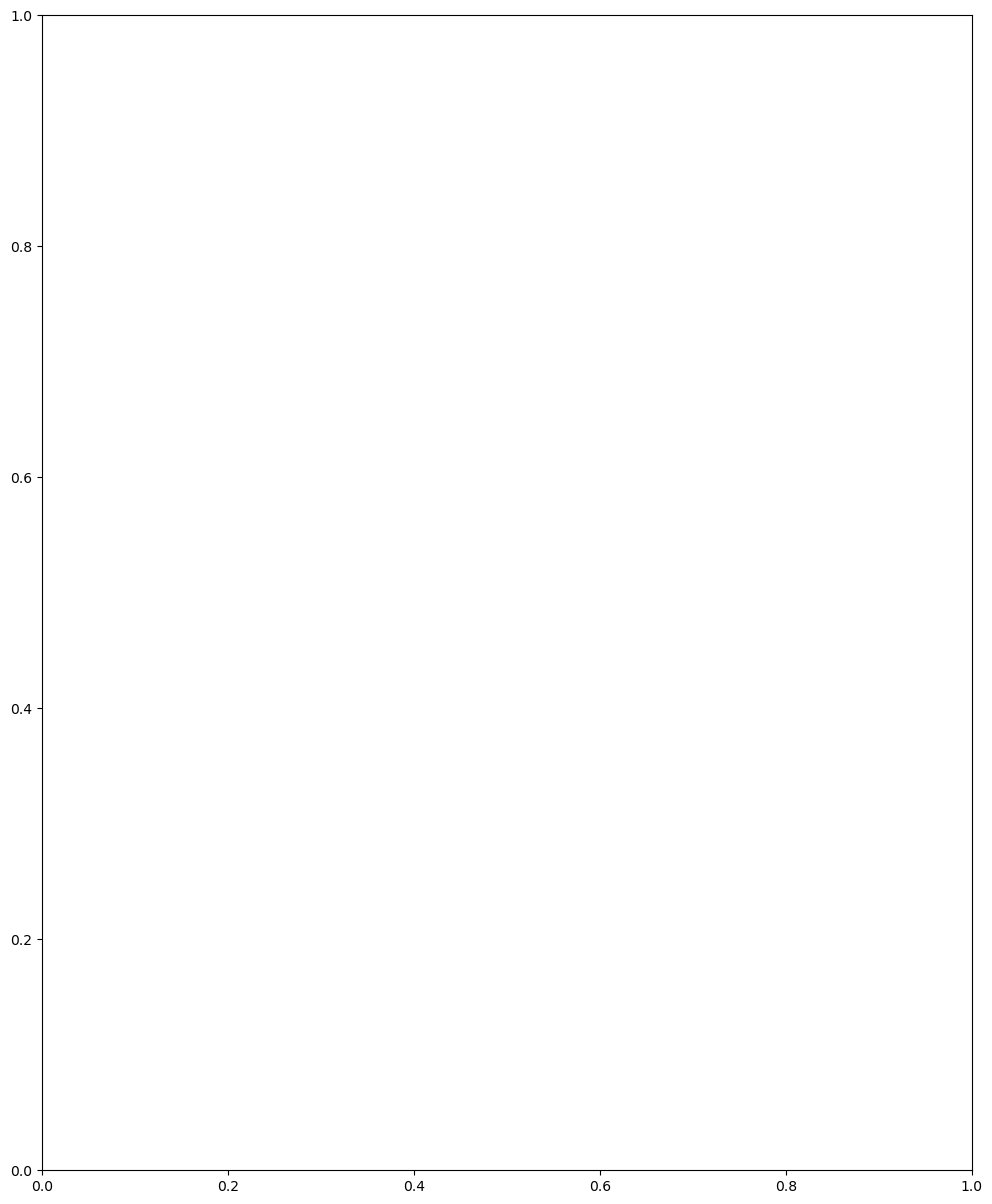

In [10]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter

df = DATA.copy()


columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_title(f"NMF, n_components: {n_components}. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

INFO:	TD maps were masked.


In [ ]:
from sklearn.cross_decomposition import CCA
import numpy as np
import nibabel as nib
from nilearn import plotting
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from KernelPCA import TD_Kernel_PCA


df = DATA.copy()

X_images = np.array(maps_all)
pca_reducer = PCA(n_components=100, random_state=42)
X_pca = pca_reducer.fit_transform(X_images)

Y = df[['OS (corrected)', 'status']].values 

cca = CCA(n_components=2)
cca.fit(X_pca, Y)

weights = cca.x_weights_
weights_voxels = pca_reducer.components_.T @ cca.x_weights_

X_cca_features, _ = cca.transform(X_pca, Y)

df_cca_features = pd.DataFrame(
    X_cca_features, 
    columns=['cca0', 'cca1']
)

data_reset = DATA.reset_index(drop=True)
df_cca_reset = df_cca_features.reset_index(drop=True)
data_with_cca = pd.concat([data_reset, df_cca_reset], axis=1)

INFO:	TD maps were masked.


In [29]:
data_with_cca

,ID,sex,age,site,volume,ltdi,tdi,OS,status,OS (corrected),cca0,cca1
0,UCSF-PDGM-009,F,68.00,0,157.513875,4.584943,125.455774,389.0,1,389.000000,1.233804,-0.024538
1,UCSF-PDGM-004,M,66.00,0,58.872375,2.269988,90.082312,1303.0,1,1303.000000,-1.049959,-1.110733
2,UCSF-PDGM-008,M,70.00,0,235.057500,5.576720,106.265873,185.0,1,185.000000,0.941358,-1.829274
3,UCSF-PDGM-011,F,68.00,0,172.138125,6.746218,132.010322,133.0,0,133.000000,-0.179902,-0.568312
4,UCSF-PDGM-014,F,64.00,0,271.585125,6.527491,95.183594,313.0,1,313.000000,0.831973,1.266326
...,...,...,...,...,...,...,...,...,...,...,...,...
858,UPENN-GBM-00605_11,M,60.38,1,127.728250,4.875498,156.613030,1565.0,1,2085.253755,-1.467100,-0.412097
859,UPENN-GBM-00608_11,F,79.90,1,158.121250,3.710009,82.003941,666.0,1,887.398723,-0.308262,1.720265
860,UPENN-GBM-00607_11,F,68.15,1,208.526250,5.742429,98.345552,1025.0,1,1365.741277,-1.090407,-0.263239
861,UPENN-GBM-00611_11,M,58.09,1,100.669500,2.627577,79.697474,551.0,1,734.169214,0.148282,0.595167


Concordance Index: 0.6619


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -3981.29
         time fit was run = 2026-03-04 19:55:28 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        1.91      6.78      0.26            1.40            2.42                4.07               11.27
cca0       3.84     46.62      0.33            3.19            4.49               24.39               89.11
cca1      -0.94      0.39      0.25           -1.43           -0.45                0.24                0.64
sex_M      0.05      1.05      0.08           -0.10            0.20                0.91                1.23

           cmp to     z      p  -log2(p)
covariate                               
age          0.00  7.37 <0.005     42.37
cca0         0.00 11.62 <0.005    101.36
cca1         0.00 -3.76 <0.005     12.50
sex_M        0.00  0.69   0.49      1.02
---
Concordance = 0.66
Partial AIC = 7970.57
log-likelihood ratio test = 201.75 on 4 df
-log2(p) of ll-ratio test = 138.86

<Axes: title={'center': 'NMF, n_components: 2. Concordance Index: 0.6619'}, xlabel='log(HR) (95% CI)'>

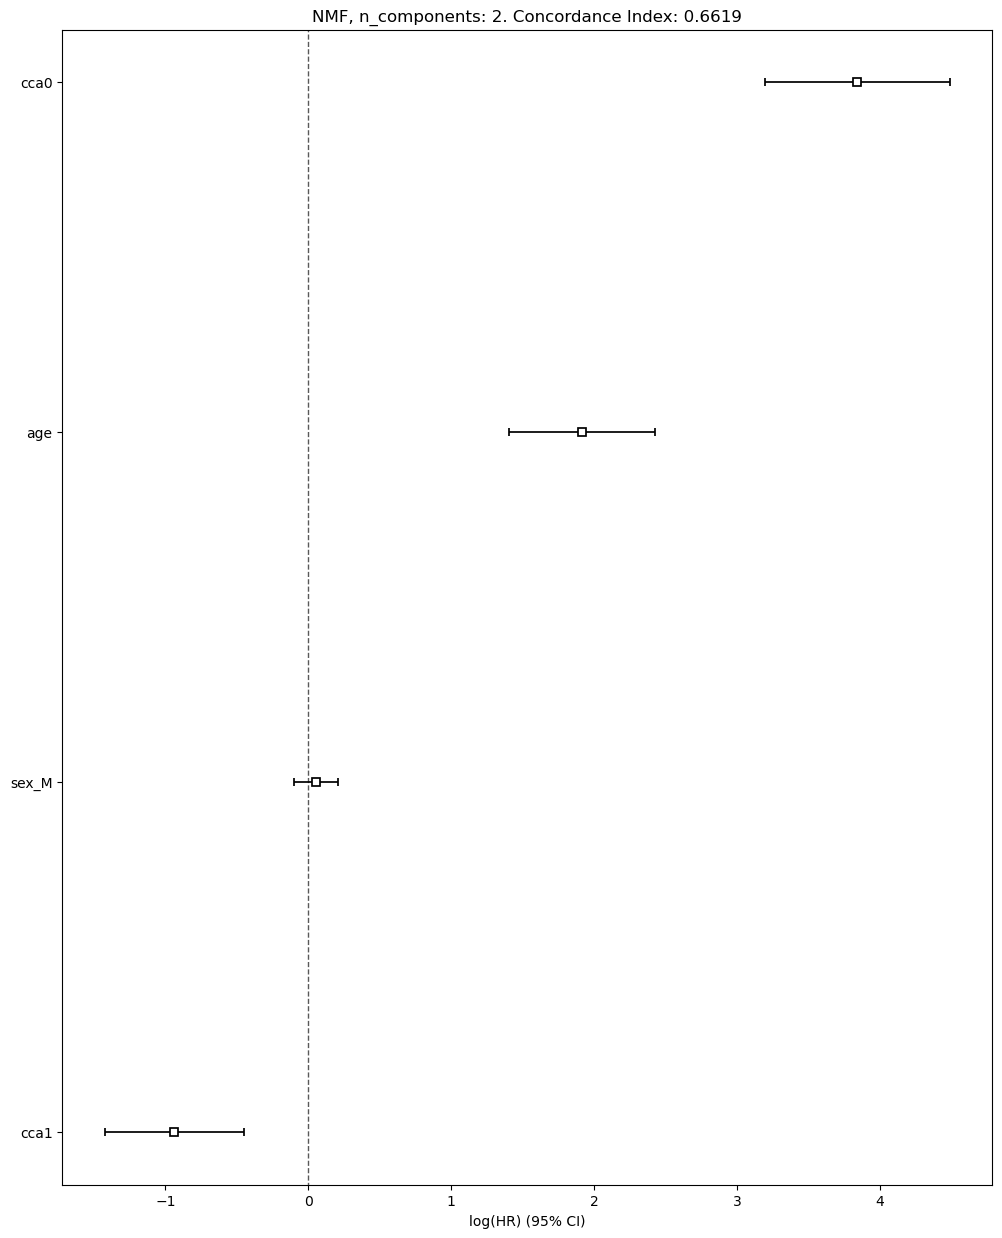

In [30]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


df = data_with_cca
columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_title(f"NMF, n_components: {2}. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

INFO:	TD maps were masked.


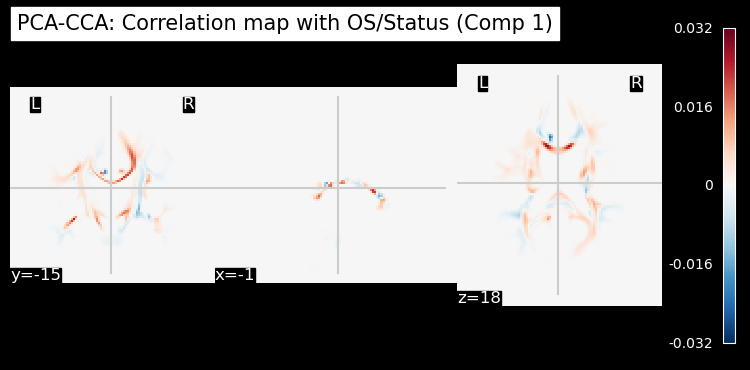

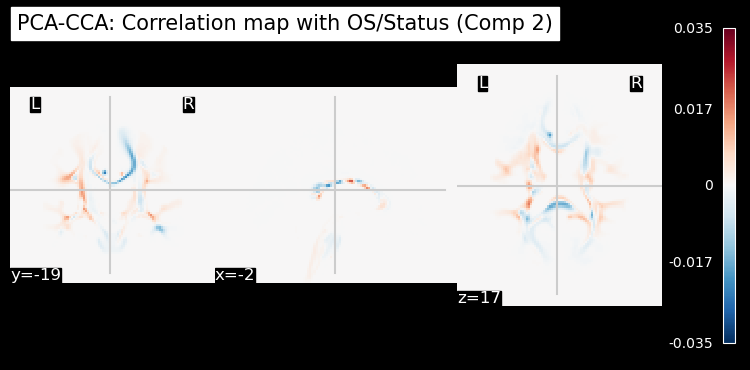

In [31]:
import numpy as np
import nibabel as nib
from nilearn import plotting, image


td_pca = TD_Kernel_PCA(maps_ucsf, T1, binary_mask=T1_brain, n_components=10)

v_shape = td_pca.template.shape

weights_to_reshape = weights_voxels.T 

if weights_to_reshape.shape[1] == np.prod(v_shape):
    spatial_cca = weights_to_reshape.reshape(2, *v_shape)
else:
    spatial_cca = td_pca.unmask(weights_to_reshape)

cca_maps_4d = np.moveaxis(spatial_cca, 0, -1)

cca_img = nib.Nifti1Image(
    cca_maps_4d.astype(np.float32), 
    td_pca.template.affine, 
    td_pca.template.header
)

for i in range(2):
    comp_img = image.index_img(cca_img, i)
    
    plotting.plot_stat_map(
        comp_img,
        title=f"PCA-CCA: Correlation map with OS/Status (Comp {i+1})",
        display_mode='ortho',
        colorbar=True,
        threshold='auto',
        bg_img=td_pca.template,
        cmap='RdBu_r'
    )

plotting.show()